# Домашнее задание 2. Выпуклость

**Выдано:** 23 сентября 2026. **Срок сдачи:** 7 октября 2026 (до начала занятия). **Максимум:** 10 баллов (+1 бонус).

**Как сдавать.** Заполните этот ноутбук (ответы на теоретические вопросы — в markdown-ячейках, формулы в $\LaTeX$; код — в code-ячейках), выполните целиком (`Kernel → Restart Kernel and Run All Cells`) и сдайте через pull request: файл `submissions/hw02/<фамилия>.ipynb`, инструкция — [`CONTRIBUTING.md`](../CONTRIBUTING.md). Задачи можно обсуждать, но текст и код пишутся самостоятельно.

**Материал:** лекция 2 ([конспект](../lectures/lecture02/lecture02.md), [демо](../lectures/lecture02/demo02.ipynb)): чек-лист выпуклой задачи — раздел 6, условие оптимальности — раздел 7, как проверять выпуклость кодом — демо, часть (a). Ничего сверх лекции не требуется. Ориентировочное время — 3–4 часа.

Запуск: `uv sync` в корне репозитория, затем `uv run jupyter lab`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize

rng = np.random.default_rng(2026)   # для ваших собственных случайных проверок; данные задач генерируются отдельно

## Задача 1. Выпуклость (4 балла)

По 1 баллу за пункт. В каждом пункте нужен либо аргумент «почему выпукло» — определение, критерий первого/второго порядка или операция из раздела 5 конспекта, — либо контрпример: две точки и вылезающий наружу отрезок, хорда под графиком или точка, где гессиан не полуопределён. Численная проверка приветствуется, но доказательством не считается (демо, часть a).

**(а) Множества.** Выпуклы ли:

1. $\{x \in \mathbb{R}^2 : x_2 \ge x_1^2\}$;
2. $\{x \in \mathbb{R}^n : \Vert Ax - b\Vert_2 \le 1\}$ при произвольных $A \in \mathbb{R}^{m \times n}$, $b \in \mathbb{R}^m$;
3. $\{x \in \mathbb{R}^2 : \Vert x\Vert_2 \ge 1\}$?

**(б) Критерий второго порядка.**

1. При каких $a \in \mathbb{R}$ функция $f(x) = x_1^2 + a\,x_1 x_2 + x_2^2$ выпукла на $\mathbb{R}^2$? При каких — строго выпукла? Проверьте ответ через `np.linalg.eigvalsh` для нескольких значений $a$.
2. Выпукла ли $g(x) = x_1^2 x_2^2$ на $\mathbb{R}^2$?

**(в) Операции.** Докажите выпуклость или объясните, почему правила раздела 5 не применимы, и приведите контрпример:

1. $f(x) = \Vert Ax - b\Vert_2 + \lambda\,\Vert x\Vert_\infty$, $\lambda \ge 0$;
2. $f(x) = \max_{i} \big(a_i^\top x - b_i\big)^2$;
3. $f(x) = e^{-\Vert x\Vert_2^2}$.

Какие из трёх функций гладкие?

**(г) Задачи ДЗ 1.** Вернитесь к задаче 1 домашнего задания 1 — пункты (а)–(г) и бонус (д). Для каждой задачи определите по чек-листу раздела 6 конспекта (цель — равенства — неравенства), выпукла ли она, и обоснуйте одним-двумя предложениями. Для невыпуклых укажите, что именно ломает выпуклость.

**(а)**

1. Множество — эпиграф функции $x_1\mapsto x_1^2$. Для допустимых $u,v$ и $0\le\theta\le1$:
   $[\theta u+(1-\theta)v]_2\ge\theta u_1^2+(1-\theta)v_1^2\ge(\theta u_1+(1-\theta)v_1)^2$. Значит, оно выпукло.
2. По неравенству треугольника $\|A(\theta u+(1-\theta)v)-b\|_2\le\theta\|Au-b\|_2+(1-\theta)\|Av-b\|_2\le1$. Множество выпукло при любых $A,b$ (включая пустое).
3. Не выпукло: $u=(1,0)$ и $v=(-1,0)$ допустимы, а их середина $(0,0)$ — нет.

**(б)**

1. $\nabla^2 f=\begin{pmatrix}2&a\\a&2\end{pmatrix}$, собственные числа $2+a$ и $2-a$. Поэтому $f$ выпукла ровно при $|a|\le2$; строго выпукла при $|a|<2$. На границе $a=\pm2$ это квадрат $(x_1\pm x_2)^2$, постоянный вдоль некоторой прямой, так что строгой выпуклости нет. Если $|a|>2$, гессиан имеет отрицательное собственное число.
2. $g$ не выпукла: $g(1,0)=g(0,1)=0$, но $g(1/2,1/2)=1/16>0$. Также $\nabla^2g=\begin{pmatrix}2x_2^2&4x_1x_2\\4x_1x_2&2x_1^2\end{pmatrix}$ имеет определитель $-12x_1^2x_2^2<0$ при $x_1x_2\ne0$.

In [2]:
for alpha in [-3.0, -2.0, -1.0, 0.0, 1.0, 2.0, 3.0]:
    eigenvalues = np.linalg.eigvalsh([[2.0, alpha], [alpha, 2.0]])
    print(f"a={alpha:4.1f}: eigenvalues={eigenvalues}")

a=-3.0: eigenvalues=[-1.  5.]
a=-2.0: eigenvalues=[0. 4.]
a=-1.0: eigenvalues=[1. 3.]
a= 0.0: eigenvalues=[2. 2.]
a= 1.0: eigenvalues=[1. 3.]
a= 2.0: eigenvalues=[0. 4.]
a= 3.0: eigenvalues=[-1.  5.]


**(в)**

1. $\|Ax-b\|_2$ выпукла как норма аффинного отображения; $\|x\|_\infty$ — норма, а $\lambda\ge0$, поэтому сумма выпукла. Обычно не гладкая: норма не дифференцируема при $Ax=b$ (если соответствующее линейное отображение не вырождено), а $\|\cdot\|_\infty$ — при равенстве максимальных модулей координат и, при $\lambda>0$, в нуле.
2. Каждая $(a_i^\top x-b_i)^2$ выпукла: её гессиан $2a_i a_i^\top\succeq0$. Поточечный максимум выпуклых функций выпукл. Обычно не гладок в точках переключения активной функции с разными градиентами; отдельные квадраты гладкие, но их максимум в общем случае нет.
3. Внешняя экспонента выпукла и возрастает, но её аргумент $-\|x\|_2^2$ вогнут, поэтому правило композиции выпуклых функций неприменимо. Более того, на прямой $x=te_1$ получаем $h(t)=e^{-t^2}$ и $h''(0)=-2<0$: функция не выпукла. Она гладкая ($C^\infty$).

Гладкой на всём пространстве без дополнительных условий на $A,b,\lambda,a_i,b_i$ гарантированно является только функция 3; функции 1 и 2 могут оказаться гладкими в специальных вырожденных случаях.

**(г)**

Проверяем именно постановки из ДЗ 1 (с областью переменных и всеми ограничениями).

- **(а)** $\min\frac12\|x-(1,2,3)\|^2$ при двух аффинных равенствах. Цель строго выпуклая (гессиан $I$), равенства аффинны, неравенств нет: выпуклая QP.
- **(б)** $\min c^\top x$ при $Ax\ge b,\ x\ge0$. Линейная цель, аффинные неравенства, равенств нет: выпуклая LP при любых данных.
- **(в)** Если $u,v\ge0$ — полуширины прямоугольника, задача $\min -4uv$ при $u^2+v^2\le1,\ u,v\ge0$. Допустимое множество выпукло, но $\nabla^2(-4uv)=\begin{pmatrix}0&-4\\-4&0\end{pmatrix}$ неопределёнен: эта постановка не выпукла (QCQP). Это не исключает *другой* выпуклой переформулировки той же геометрической задачи.
- **(г)** $\min\frac12\sum_i[x_1\sin(x_2t_i+x_3)-y_i]^2$ без ограничений. Равенств/неравенств нет, цель в общем случае невыпукла из-за неизвестных частоты и фазы: NLP. Ненулевая зависимость от фазы периодична, а выпуклая на всей прямой периодическая функция должна быть постоянной.
- **(д, бонус)** Введение $s$ даёт $\min_{x,s}s$ при $s-(a_i^\top x-b_i)\ge0$ и $s+(a_i^\top x-b_i)\ge0$ для всех $i$. Цель и неравенства аффинны, равенств нет: выпуклая LP. Исходная цель $\max_i|a_i^\top x-b_i|$ также выпукла как максимум выпуклых модулей аффинных функций.

## Задача 2. Практика (6 баллов)

**(а) Проекция на полупространство (3 балла).** Пусть $\Omega = \{x \in \mathbb{R}^n : a^\top x \le b\}$, $a \ne 0$, и точка $p$ лежит вне $\Omega$, то есть $a^\top p > b$. Задача проекции — $\min_{x \in \Omega} \tfrac12\Vert x - p\Vert^2$ (раздел 7 конспекта, пример 2).

1. Из условия оптимальности $\nabla f(x^\ast)^\top(y - x^\ast) \ge 0\ \ \forall y \in \Omega$ выведите явную формулу

$$x^\ast = p - \frac{a^\top p - b}{\Vert a\Vert^2}\, a .$$

Подсказки: (i) почему $x^\ast$ не может лежать строго внутри $\Omega$; (ii) для любого $v$ с $a^\top v = 0$ точки $y = x^\ast \pm v$ допустимы — что даёт условие для них; (iii) коэффициент при $a$ найдите из $a^\top x^\ast = b$; (iv) убедитесь, что при таком коэффициенте условие выполнено и для всех остальных $y \in \Omega$ — тогда, по теореме раздела 7, $x^\ast$ действительно решение.

2. Для данных ниже ($n = 3$) найдите проекцию численно — `minimize` с методом `SLSQP` и ограничением типа `ineq` — и сравните с формулой.

3. Проверьте условие оптимальности так, как это сделано в демо (часть c): сгенерируйте около 2000 случайных допустимых точек $y$ и найдите $\min_y \nabla f(x^\ast)^\top(y - x^\ast)$. Повторите для заведомо неоптимальной допустимой точки, например $x = 0$. Что означает знак результата в каждом случае?

In [3]:
a = np.array([1.0, 2.0, -1.0])     # нормаль полупространства
b = 1.0
p = np.array([3.0, 1.0, 0.5])      # точка вне Omega: a @ p = 4.5 > b
assert a @ p > b

**Вывод формулы (пункт 1)**

Так как $p$ не допустима, проекция не может лежать строго внутри полупространства: если бы $a^\top x^*<b$, условие оптимальности для всех малых направлений $\pm v$ давало бы $\nabla f(x^*)=x^*-p=0$, то есть $x^*=p$, противоречие. Следовательно, $a^\top x^*=b$.

Для всякого $v$ с $a^\top v=0$ обе точки $x^*\pm v$ допустимы. Из условия оптимальности для этих двух точек следует $(x^*-p)^\top v=0$. Значит, $x^*-p=-\tau a$ для некоторого $\tau$. Из $a^\top x^*=b$ получаем $\tau=(a^\top p-b)/\|a\|^2>0$ и формулу
$$x^*=p-\frac{a^\top p-b}{\|a\|^2}a.$$
Для любого $y\in\Omega$ имеем $(x^*-p)^\top(y-x^*)=-\tau(a^\top y-b)\ge0$. Это достаточное условие для выпуклой цели на выпуклом множестве; строго выпуклая квадратичная цель даёт единственную проекцию.

**Численная проверка (пункты 2 и 3)**

In [4]:
tau = (a @ p - b) / (a @ a)
x_star = p - tau * a
constraint = {"type": "ineq", "fun": lambda x: b - a @ x,
              "jac": lambda x: -a}
result = minimize(lambda x: 0.5 * np.sum((x - p)**2), p,
                  jac=lambda x: x - p, constraints=[constraint],
                  method="SLSQP", options={"ftol": 1e-12})
assert result.success, result.message
assert a @ result.x <= b + 1e-10
assert np.allclose(result.x, x_star, atol=1e-8)
print("formula:", x_star, "numerical:", result.x)
print("distance between solutions:", np.linalg.norm(result.x - x_star))

# Projection maps all randomly chosen candidates into Omega, yielding 2000 feasible y.
check_rng = np.random.default_rng(2027)
candidates = check_rng.normal(size=(2000, 3)) * 2.0
y_feasible = candidates - (np.maximum(candidates @ a - b, 0) / (a @ a))[:, None] * a
assert np.all(y_feasible @ a <= b + 1e-12)
at_optimum = (y_feasible - x_star) @ (x_star - p)
at_zero = y_feasible @ (-p)  # x=0 is feasible because 0 <= b
print("minimum optimality scalar product at x*:", at_optimum.min())
print("minimum optimality scalar product at x=0:", at_zero.min())
assert at_optimum.min() >= -1e-10 and at_zero.min() < -1e-3

formula: [ 2.41666667 -0.16666667  1.08333333] numerical: [ 2.41666667 -0.16666667  1.08333333]
distance between solutions: 8.308148362110449e-16
minimum optimality scalar product at x*: -1.5570025020495953e-15
minimum optimality scalar product at x=0: -18.61101755609239


Проекция по формуле — $(29/12,-1/6,13/12)$: $a^\top x^*=1$. SLSQP возвращает ту же точку с точностью численного округления. У $x^*$ проверенные скалярные произведения неотрицательны (минимум может быть порядка $10^{-15}$ из-за округления); более того, вывод формулы доказывает это для **всех** допустимых $y$. У допустимой точки $x=0$ обнаруживается отрицательное произведение, поэтому она не оптимальна: существует допустимое направление уменьшения цели.

**(б) Выпуклая и невыпуклая подгонка (3 балла).** Ниже сгенерированы измерения $y_i = 2\sin(3t_i + 0.7) + \varepsilon_i$, $\varepsilon_i \sim \mathcal{N}(0, 0.2^2)$, $i = 1, \dots, 60$. Один и тот же сигнал описываем двумя моделями:

- **A** (задача 1(г) ДЗ 1): $\varphi_A(t; x) = x_1 \sin(x_2 t + x_3)$, $x \in \mathbb{R}^3$ — амплитуда, частота и фаза неизвестны;
- **B** (частота известна, $\omega = 3$): $\varphi_B(t; x) = x_1 \sin\omega t + x_2 \cos\omega t$, $x \in \mathbb{R}^2$.

Цель в обоих случаях — сумма квадратов невязок $f(x) = \tfrac12\sum_i \big(\varphi(t_i; x) - y_i\big)^2$.

1. Какого класса каждая задача и выпукла ли она? Для B — докажите; для A — объясните, почему нет (подсказка: что происходит с $f$ при $x_3 \to x_3 + 2\pi$ и при $(x_1, x_3) \to (-x_1, x_3 + \pi)$?).
2. Запустите `minimize(..., method="BFGS")` для обеих моделей из 20 одинаковых случайных стартов `starts` (для B берите первые две координаты старта). Выведите итоговые значения $f$ по стартам и долю стартов, пришедших к наименьшему найденному значению; нарисуйте данные и подогнанные кривые для обеих моделей.
3. Объясните результат через главную теорему лекции. Как из решения B получить амплитуду и фазу для модели A? Почему наименьшее найденное $f$ у A чуть меньше, чем у B, и почему это не делает A «лучшей» задачей?

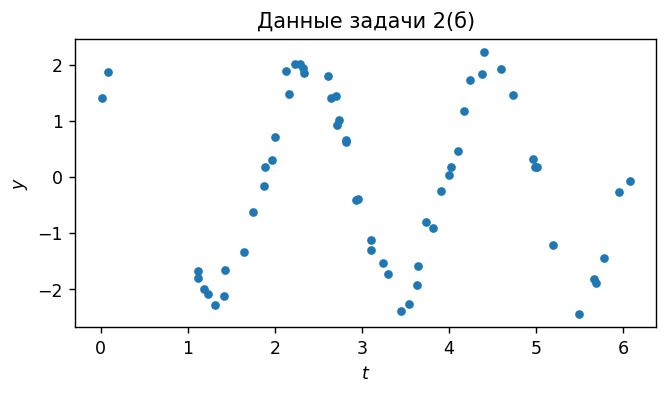

In [5]:
data_rng = np.random.default_rng(2026)          # отдельный генератор: данные не зависят от вашего кода выше
N, omega = 60, 3.0
t = np.sort(data_rng.uniform(0, 2 * np.pi, N))
y = 2.0 * np.sin(3.0 * t + 0.7) + 0.2 * data_rng.standard_normal(N)
starts = data_rng.uniform(-5, 5, (20, 3))         # 20 общих стартов для обеих моделей

plt.figure(figsize=(6, 3))
plt.plot(t, y, "o", ms=4)
plt.xlabel("$t$"); plt.ylabel("$y$"); plt.title("Данные задачи 2(б)")
plt.show()

**Класс и выпуклость (пункт 1)**

Обе постановки — безусловный нелинейный МНК. Для B обозначим $X_{i,:}=(\sin3t_i,\cos3t_i)$: $f_B(z)=\tfrac12\|Xz-y\|^2$, $\nabla^2 f_B=X^\top X\succeq0$. Здесь два столбца $X$ линейно независимы, так что гессиан положительно определён и единственный минимум глобален.

Для A цель в общем случае невыпукла. При фиксированной ненулевой амплитуде зависимость от фазы $x_3$ периодична с периодом $2\pi$ и не постоянна; такая функция на всей прямой не может быть выпуклой. Дополнительная симметрия $(x_1,x_3)\mapsto(-x_1,x_3+\pi)$ даёт одинаковые предсказания в разных точках, а неизвестная частота создаёт разные локальные минимумы.

**Мультистарт (пункт 2)**

A: final f for 20 starts: [ 1.13927 63.82489  1.13927  1.13927  1.13927 61.49727 61.49727 64.25178
  1.13927 63.82489  1.13927  1.13927 61.49727  1.13927 64.25178  1.13927
 61.68817  1.13927 61.49727  1.13927]
A: best f=1.13927310; fraction near best=55% (11/20)
B: final f for 20 starts: [1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076
 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076 1.14076
 1.14076 1.14076]
B: best f=1.14076401; fraction near best=100% (20/20)
best A parameters: [2.10139254 2.99669062 6.98344926] ; best B parameters: [1.6234269  1.33780773]
A: BFGS runs with convergence warning (run, gradient norm): [(2, 0.050036), (7, 0.0), (10, 0.094359), (11, 2e-06), (12, 0.0), (13, 0.0), (15, 0.0), (16, 0.0), (19, 1e-06)]
B: BFGS runs with convergence warning (run, gradient norm): [(3, 0.0)]


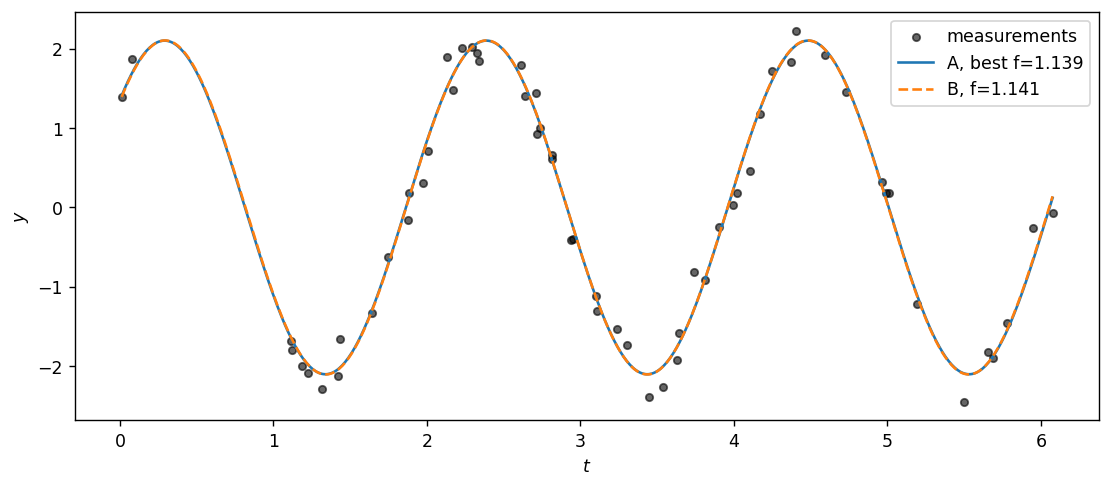

In [6]:
def model_a(params, times):
    amplitude, frequency, phase = params
    return amplitude * np.sin(frequency * times + phase)

def model_b(params, times):
    return params[0] * np.sin(omega * times) + params[1] * np.cos(omega * times)

def loss_a(params):
    residual = model_a(params, t) - y
    return 0.5 * residual @ residual

def gradient_a(params):
    amplitude, frequency, phase = params
    angle = frequency * t + phase
    residual = model_a(params, t) - y
    jacobian = np.column_stack((np.sin(angle),
                                amplitude * t * np.cos(angle),
                                amplitude * np.cos(angle)))
    return jacobian.T @ residual

design = np.column_stack((np.sin(omega * t), np.cos(omega * t)))
def loss_b(params):
    residual = design @ params - y
    return 0.5 * residual @ residual

def gradient_b(params):
    return design.T @ (design @ params - y)

runs_a = [minimize(loss_a, start, jac=gradient_a, method="BFGS",
                   options={"gtol": 1e-8, "maxiter": 2000}) for start in starts]
runs_b = [minimize(loss_b, start[:2], jac=gradient_b, method="BFGS",
                   options={"gtol": 1e-8, "maxiter": 2000}) for start in starts]
values_a = np.array([run.fun for run in runs_a])
values_b = np.array([run.fun for run in runs_b])
best_a = runs_a[np.argmin(values_a)].x
best_b = runs_b[np.argmin(values_b)].x

for label, values in (("A", values_a), ("B", values_b)):
    near_best = np.isclose(values, values.min(), rtol=1e-5, atol=1e-5)
    print(f"{label}: final f for 20 starts: {np.array2string(values, precision=5)}")
    print(f"{label}: best f={values.min():.8f}; fraction near best={near_best.mean():.0%} "
          f"({near_best.sum()}/20)")
print("best A parameters:", best_a, "; best B parameters:", best_b)
for label, runs in (("A", runs_a), ("B", runs_b)):
    flagged = [(i + 1, round(float(np.linalg.norm(run.jac)), 6))
               for i, run in enumerate(runs) if not run.success]
    print(f"{label}: BFGS runs with convergence warning (run, gradient norm): {flagged}")
assert np.linalg.matrix_rank(design) == 2
assert np.allclose(best_b, np.linalg.lstsq(design, y, rcond=None)[0], atol=1e-6)
assert values_a.min() <= values_b.min() + 1e-7

tt = np.linspace(t.min(), t.max(), 600)
plt.figure(figsize=(9, 4))
plt.scatter(t, y, s=18, color="black", alpha=0.6, label="measurements")
plt.plot(tt, model_a(best_a, tt), label=f"A, best f={values_a.min():.3f}")
plt.plot(tt, model_b(best_b, tt), "--", label=f"B, f={values_b.min():.3f}")
plt.xlabel("$t$"); plt.ylabel("$y$"); plt.legend(); plt.tight_layout(); plt.show()

**Объяснение (пункт 3)**

В B стационарная точка — глобальный минимум, потому что цель выпукла; более того, $X^\top X\succ0$ обеспечивает её единственность. Поэтому все старты B дают одно значение и те же коэффициенты. В A BFGS может попадать в разные локальные минимумы; разброс итоговых значений отражает невыпуклость. Доля посчитана по значению цели относительно наименьшего *найденного* значения — она не доказывает, что это глобальный минимум A. Отдельные вызовы BFGS сообщают о потере точности либо о лимите итераций: их конечные значения выведены, но сообщение оптимизатора не следует принимать за подтверждение локального минимума. У запусков с малым градиентом численное значение может быть устойчивым даже при таком предупреждении.

Если $z=(z_1,z_2)$ — решение B, то при частоте $3$ параметры A можно взять как
$$R=\sqrt{z_1^2+z_2^2},\qquad \phi=\operatorname{atan2}(z_2,z_1),\qquad (x_1,x_2,x_3)=(R,3,\phi),$$
поскольку $R\sin(3t+\phi)=z_1\sin3t+z_2\cos3t$. При $R=0$ фаза произвольна. Таким образом, семейство A содержит B и истинный глобальный минимум A не хуже B. У найденного решения A значение немного меньше за счёт настройки ещё и частоты под шум. Это дополнительная гибкость, которая может подгонять шум; невыпуклая оптимизация чувствительна к старту и не гарантирует глобального решения. Меньшая ошибка на этих же обучающих данных сама по себе не означает лучшую модель или предсказание.

## Бонус (+1 балл). Проекция не растягивает

Пусть $\Omega$ — выпуклое замкнутое множество, $P(p)$ — проекция точки $p$ на $\Omega$ (решение задачи $\min_{x \in \Omega} \tfrac12\Vert x - p\Vert^2$). Докажите, что для любых $p, q$

$$\Vert P(p) - P(q)\Vert \le \Vert p - q\Vert .$$

Подсказка: запишите условие оптимальности для $P(p)$ с пробной точкой $y = P(q)$ и для $P(q)$ с $y = P(p)$, сложите и примените неравенство Коши–Буняковского. Проверьте численно на шаре ($P(p) = p / \max(1, \Vert p\Vert)$) и на кубе $[-1, 1]^n$ (`np.clip`) для 1000 случайных пар точек.

Обозначим $u=P(p)$, $v=P(q)$. Условие оптимальности проекции даёт
$$(u-p)^\top(v-u)\ge0,\qquad (v-q)^\top(u-v)\ge0.$$
После сложения и перестановки:
$$\|u-v\|^2\le(p-q)^\top(u-v)\le\|p-q\|\,\|u-v\|.$$
При $u\ne v$ делим на $\|u-v\|$; при $u=v$ утверждение очевидно. Замкнутость непустого множества обеспечивает существование проекции, выпуклость — её единственность и достаточность условия оптимальности.

In [7]:
pair_rng = np.random.default_rng(2028)
p_pairs = pair_rng.normal(size=(1000, 5)) * 3.0
q_pairs = pair_rng.normal(size=(1000, 5)) * 3.0

def ball_projection(points):
    return points / np.maximum(1.0, np.linalg.norm(points, axis=1, keepdims=True))

for name, projection in (("unit ball", ball_projection),
                         ("cube [-1,1]^5", lambda points: np.clip(points, -1, 1))):
    projected_distance = np.linalg.norm(projection(p_pairs) - projection(q_pairs), axis=1)
    original_distance = np.linalg.norm(p_pairs - q_pairs, axis=1)
    excess = np.max(projected_distance - original_distance)
    print(f"{name}: maximum distance increase among 1000 pairs = {excess:.3e}")
    assert excess <= 1e-12

unit ball: maximum distance increase among 1000 pairs = -1.053e+00
cube [-1,1]^5: maximum distance increase among 1000 pairs = -6.443e-02


---

Перед сдачей: `Kernel → Restart Kernel and Run All Cells`, убедитесь, что ни одна ячейка не падает и все ответы заполнены. Файл — `submissions/hw02/<фамилия>.ipynb`, дальше по [инструкции](../CONTRIBUTING.md).